**CodeAlpha Internship, Task 3: Data Visualization**.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import os

sns.set_theme(style="whitegrid", palette="viridis")
os.makedirs("images", exist_ok=True)

df = pd.read_csv("C:/Users/ACER/Codealpha_Visualization/Data/SuperStoreOrders.csv")   # use your real file name/path

df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("-", "_")
df['sales'] = pd.to_numeric(
    df['sales'].astype(str).str.replace(r'[^\d.\-]', '', regex=True), errors='coerce')
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', dayfirst=True, errors='coerce')
df['ship_date']  = pd.to_datetime(df['ship_date'],  format='mixed', dayfirst=True, errors='coerce')
df = df.drop_duplicates()
df = df.dropna(subset=['sales', 'order_date'])
df['month'] = df['order_date'].dt.to_period('M').dt.to_timestamp()

print(df.shape)

(51290, 22)


Monthly Sales Trend

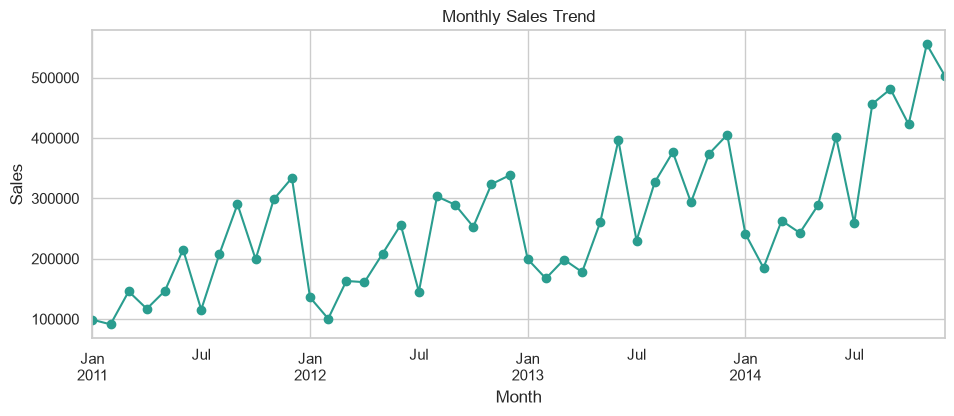

2014-11-01 00:00:00 555312
order_date
1      675141
2      543768
3      770519
4      698603
5      904061
6     1269751
7      749423
8     1293852
9     1437432
10    1168220
11    1551319
12    1580816
Name: sales, dtype: int64
order_date
2011    2259511
2012    2677493
2013    3405860
2014    4300041
Name: sales, dtype: int64
order_date
2011     NaN
2012    18.5
2013    27.2
2014    26.3
Name: sales, dtype: float64


In [2]:
monthly = df.groupby('month')['sales'].sum()
plt.figure(figsize=(11,4))
monthly.plot(marker='o', color='#2a9d8f')
plt.title("Monthly Sales Trend"); plt.xlabel("Month"); plt.ylabel("Sales")
plt.savefig("images/01_monthly_sales.png", dpi=300, bbox_inches="tight"); plt.show()
print(monthly.idxmax(), round(monthly.max()))

season = df.groupby(df['order_date'].dt.month)['sales'].sum()
print(season)

yearly = df.groupby(df['order_date'].dt.year)['sales'].sum()
print(yearly)
print((yearly.pct_change()*100).round(1))

**Insight:** Sales grew every year, from 2.26M in 2011 to 4.30M in 2014 (about 90% growth), with yearly growth of 18.5%, 27.2% and 26.3%. Sales are strongly seasonal: November and December are the peak months (about 25% of all sales together), while January and February are the weakest.

Sales and profit by category


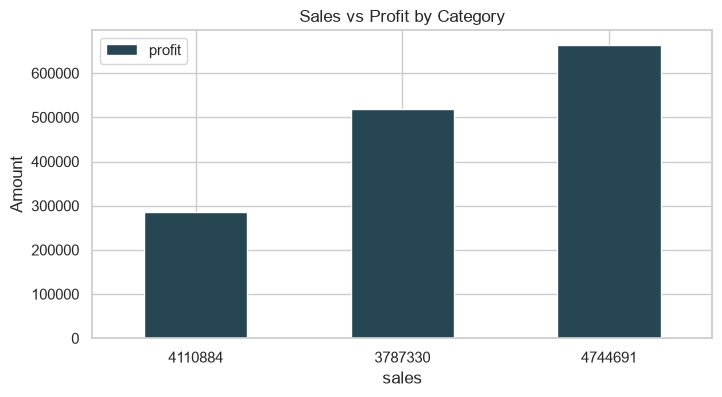

          category    sales        profit
0        Furniture  4110884  286782.25380
1  Office Supplies  3787330  518473.83430
2       Technology  4744691  663778.73318


In [3]:
cat=df.groupby('category')[['sales','profit']].sum().reset_index()
cat.plot(x='sales',kind='bar',figsize=(8,4),color=['#264653','#e9c46a'])
plt.title('Sales vs Profit by Category');
plt.ylabel('Amount');
plt.xticks(rotation=0)
plt.savefig("images/02_category.png", dpi=300, bbox_inches="tight");
plt.show()
print(cat)





**Insight:** Technology is the top category by sales (about 4.71M, 37% of total), followed by Furniture (4.14M) and Office Supplies (3.79M). Sales are fairly balanced across the three categories, but Technology also leads in profit, making it the strongest contributor to the business.

cells share by segment

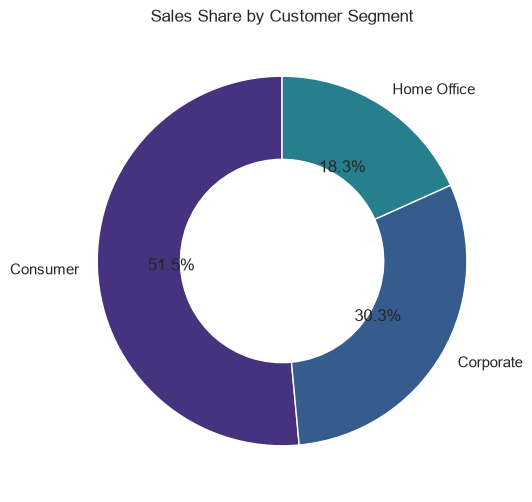

In [4]:
seg = df.groupby('segment')['sales'].sum()
plt.figure(figsize=(6,6))
plt.pie(seg, labels=seg.index, autopct='%1.1f%%', startangle=90,
        wedgeprops=dict(width=0.45))
plt.title("Sales Share by Customer Segment")
plt.savefig("images/03_segment.png", dpi=300, bbox_inches="tight"); plt.show()

**Insight:** Consumers are the largest customer segment, contributing 51.5% of total sales. Corporate follows with 30.3%, and Home Office is the smallest at 18.3%. The business depends mainly on individual buyers, so consumer-focused promotions will have the biggest impact on sales.

Total sales by market

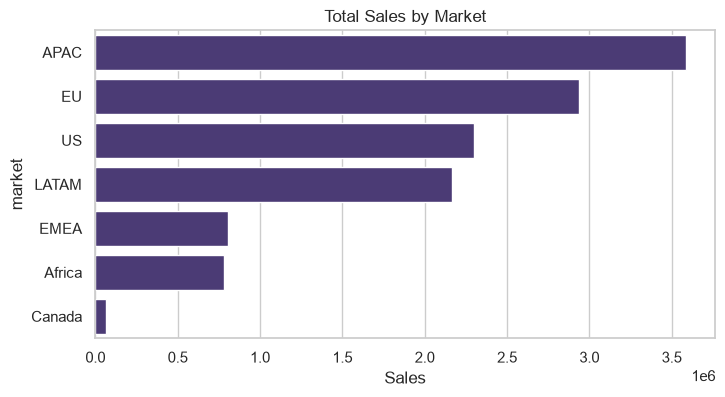

In [5]:
mk = df.groupby('market')['sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,4))
sns.barplot(x=mk.values, y=mk.index)
plt.title("Total Sales by Market"); plt.xlabel("Sales")
plt.savefig("images/04_market.png", dpi=300, bbox_inches="tight"); plt.show()

**Insight:** APAC is the largest market with about 3.5M in sales (roughly 28% of the total), while Canada is the smallest, contributing only a small fraction. Sales are concentrated in a few large markets, so growth efforts there will have the biggest impact.

profit distribution

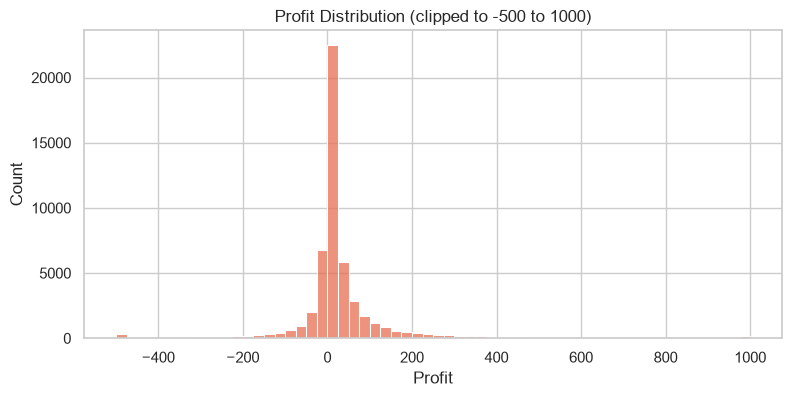

Loss-making orders:  24.5 %


In [6]:
plt.figure(figsize=(9,4))
sns.histplot(df['profit'].clip(-500, 1000), bins=60, color='#e76f51')
plt.title("Profit Distribution (clipped to -500 to 1000)"); plt.xlabel("Profit")
plt.savefig("images/05_profit_hist.png", dpi=300, bbox_inches="tight"); plt.show()
print("Loss-making orders: ", round((df['profit']<0).mean()*100,1), "%")

**Insight:** Most orders earn a small profit close to zero, while a small number of high-profit orders form a long tail to the right. A noticeable group of orders makes a loss, and the bar at -500 holds the orders that lost 500 or more (values below -500 are clipped into that bar). This shows that profit depends on a few large orders, and that heavy losses on some orders reduce overall profit.

Correlation heatmap


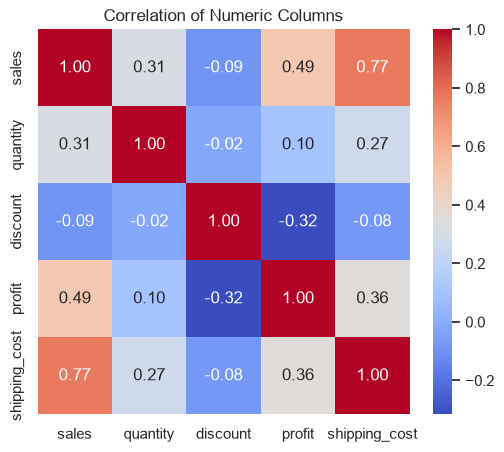

In [7]:
num = df[['sales','quantity','discount','profit','shipping_cost']]
plt.figure(figsize=(6,5))
sns.heatmap(num.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation of Numeric Columns")
plt.savefig("images/06_heatmap.png", dpi=300, bbox_inches="tight"); plt.show()

**Insight:** Sales and shipping cost are strongly related (0.77), so larger orders cost more to ship. Discount is negatively related to profit (-0.32) and barely affects sales (-0.09), so heavy discounts reduce profit without boosting sales.

profit outliers by category

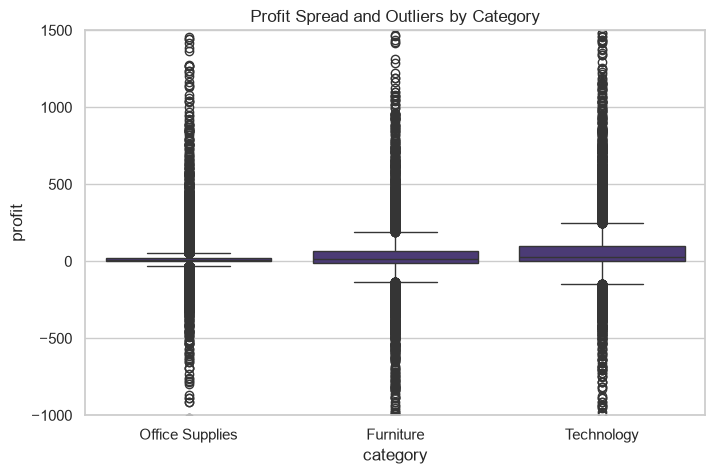

In [8]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='category', y='profit')
plt.ylim(-1000, 1500)
plt.title("Profit Spread and Outliers by Category")
plt.savefig("images/07_boxplot.png", dpi=300, bbox_inches="tight"); plt.show()

**Insight (Outlier Detection):** Office Supplies profit is tightly clustered near zero, while Technology has the highest median profit and widest spread. All three categories have many high-value and loss-making outliers, so profitability varies a lot between orders.

, top 10 products by profit

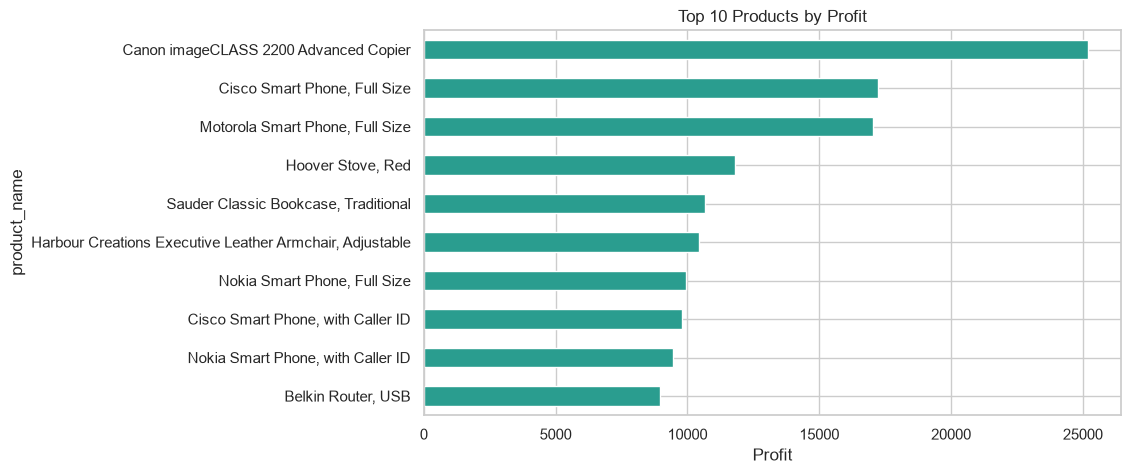

In [9]:
top = df.groupby('product_name')['profit'].sum().nlargest(10).sort_values()
plt.figure(figsize=(9,5))
top.plot(kind='barh', color='#2a9d8f')
plt.title("Top 10 Products by Profit"); plt.xlabel("Profit")
plt.savefig("images/08_top_products.png", dpi=300, bbox_inches="tight"); plt.show()

**Insight (Product Performance Analysis):** Technology products dominate the top 10 (7 of 10), led by the Canon imageCLASS 2200 copier at around 25,000 in profit. Phones from Cisco, Motorola and Nokia are the next biggest profit drivers.

how discount affects profit

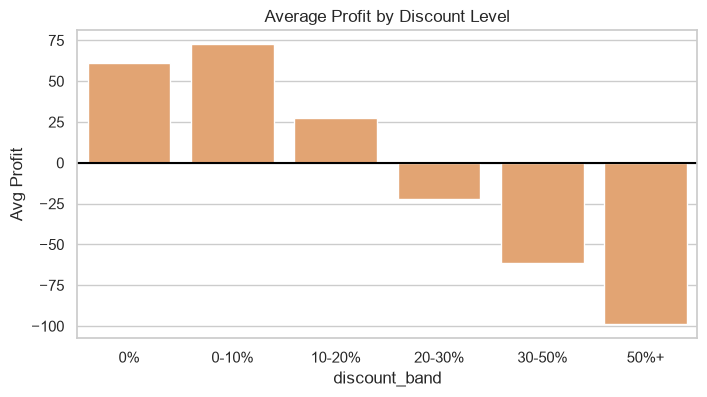

discount_band
0%        61.04
0-10%     72.62
10-20%    27.61
20-30%   -21.88
30-50%   -61.55
50%+     -98.89
Name: profit, dtype: float64


In [10]:
df['discount_band'] = pd.cut(df['discount'], [-0.01,0,0.1,0.2,0.3,0.5,1],
                             labels=['0%','0-10%','10-20%','20-30%','30-50%','50%+'])
d = df.groupby('discount_band', observed=True)['profit'].mean()
plt.figure(figsize=(8,4))
sns.barplot(x=d.index, y=d.values, color='#f4a261')
plt.axhline(0, color='black'); plt.title("Average Profit by Discount Level")
plt.ylabel("Avg Profit")
plt.savefig("images/09_discount_profit.png", dpi=300, bbox_inches="tight"); plt.show()
print(d.round(2))

**Insight (Pricing Strategy and Discount Optimization):** Average profit is highest at 0-10% discount and turns negative above 20%, reaching about -100 per order at 50%+. Heavy discounting leads to losses, so a discount cap is recommended.

## Conclusion and Recommendations

**Key findings**
- Sales grew every year, from 2.26M (2011) to 4.30M (2014), about 90% growth.
- Nov and Dec are the peak months; Jan and Feb are the weakest.
- Consumer is the largest segment (51.5% of sales).
- APAC is the top market; Technology is the top category.
- Discounts above 20% lead to negative average profit.

**Recommendations**
- Build up stock and run campaigns before Sep-Dec.
- Cap discounts at around 20% to protect profit.
- Review shipping costs on large orders.
- Focus marketing on Consumer, and grow Corporate with bulk-order offers.